# Analysis of Unstructured Data: Problem Set 2

**Neural networks & optimisation**

Theory answers (Problems 1–3) and the written analysis (Problem 7) are in Markdown cells. All numbers and figures are reproduced by running the notebook top to bottom (about 6–8 minutes on a CPU, most of it in Problem 6).

Dependencies: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `torch`. No internet connection is needed.

**Data.** As in Problem Set 1, the features are the 64 pixel intensities of the scikit-learn `digits` dataset (1797 images of $8\times8$ pixels, 10 classes). Intensities are divided by 16, so every feature lies in $[0,1]$. This is a fixed constant, not a statistic estimated from the data, so it cannot leak information between splits. The data are split once, stratified by class, into 60% training, 20% validation and 20% test.

### Notation used throughout

| Symbol | Meaning |
|---|---|
| $x\in\mathbb{R}^d$ | one input (column vector); here $d=64$ |
| $K$ | number of classes; here $K=10$ |
| $m$ | number of hidden units |
| $y\in\{0,1\}^K$ | one-hot target: $y=e_c$ for true class $c$, where $e_c$ is the $c$-th standard basis vector |
| $\delta_{ki}$ | Kronecker delta: 1 if $k=i$, 0 otherwise |
| $u\odot v$ | elementwise (Hadamard) product |
| $\mathbf 1$ | vector of ones |
| $\dfrac{\partial L}{\partial W}$ | for a scalar $L$ and a matrix $W$: the matrix of the **same shape** as $W$ with entries $\partial L/\partial W_{ij}$ |

All logarithms are natural.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 42
torch.set_default_dtype(torch.float64)  # float64 everywhere, so NumPy and PyTorch can agree to ~1e-15

SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948",
)

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.edgecolor": GRID, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.6,
    "legend.frameon": False,
})

digits = load_digits()
X_all, y_all = digits.data / 16.0, digits.target
X_train, X_rest, y_train, y_rest = train_test_split(X_all, y_all, test_size=0.4, stratify=y_all, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=SEED)

D_IN, N_CLASSES = X_all.shape[1], len(np.unique(y_all))
pd.DataFrame({"images": [len(y_train), len(y_val), len(y_test)]}, index=["train", "validation", "test"])

,images
train,1078
validation,359
test,360


## Problem 1 [Theory]: Softmax + cross-entropy

### Setting

A classifier with $K$ classes outputs a vector of **logits** $z\in\mathbb{R}^K$, i.e. arbitrary real scores, one per class. Softmax turns them into probabilities:

$$
p_k=\operatorname{softmax}(z)_k=\frac{e^{z_k}}{\sum_{j=1}^K e^{z_j}},\qquad k=1,\dots,K.
$$

Every $p_k>0$ and $\sum_k p_k=1$, so $p$ is a probability distribution over the classes. Adding the same constant to all logits does not change $p$, because the factor $e^{c}$ cancels between numerator and denominator.

The target is one-hot, $y=e_c$ for the true class $c$, and the cross-entropy loss is

$$
L=-\sum_{k=1}^K y_k\log p_k=-\log p_c .
$$

It is small when the model gives the true class a high probability, and it tends to $+\infty$ as $p_c\to0$.

### Derivation of $\partial L/\partial z = p-y$

**Step 1: remove the fraction.** Taking the log of the softmax gives

$$
\log p_k=z_k-\operatorname{LSE}(z),\qquad \operatorname{LSE}(z):=\log\sum_{j=1}^K e^{z_j}\quad(\text{"log-sum-exp"}).
$$

Substituting into $L$ and using $\sum_k y_k=1$:

$$
L=-\sum_k y_k z_k+\Big(\sum_k y_k\Big)\operatorname{LSE}(z)=-y^\top z+\operatorname{LSE}(z).
$$

**Step 2: differentiate.** For a fixed index $i$,

$$
\frac{\partial}{\partial z_i}\,y^\top z=y_i,
\qquad
\frac{\partial}{\partial z_i}\operatorname{LSE}(z)=\frac{1}{\sum_j e^{z_j}}\cdot e^{z_i}=p_i .
$$

Therefore

$$
\boxed{\;\frac{\partial L}{\partial z_i}=p_i-y_i,\qquad\text{i.e.}\qquad \nabla_z L=p-y.\;}\qquad\blacksquare
$$

The proof used only $\sum_k y_k=1$, so the same formula holds for any probability vector $y$ as a target, for example soft labels or label smoothing.

**The same result through the softmax Jacobian.** It is instructive to do the computation the "long way", because it shows *what cancels*. By the quotient rule,

$$
\frac{\partial p_k}{\partial z_i}=\frac{\delta_{ki}e^{z_k}\sum_j e^{z_j}-e^{z_k}e^{z_i}}{\left(\sum_j e^{z_j}\right)^2}=p_k(\delta_{ki}-p_i).
$$

In matrix form the Jacobian is $J=\dfrac{\partial p}{\partial z}=\operatorname{diag}(p)-pp^\top$, which is symmetric. Then, by the chain rule,

$$
\frac{\partial L}{\partial z_i}=\sum_k\frac{\partial L}{\partial p_k}\frac{\partial p_k}{\partial z_i}
=\sum_k\left(-\frac{y_k}{p_k}\right)p_k(\delta_{ki}-p_i)
=-\sum_k y_k\delta_{ki}+p_i\sum_k y_k
=p_i-y_i .
$$

The factor $1/p_k$ coming from the logarithm cancels exactly against the factor $p_k$ coming from the exponential in the softmax.

**Reading the formula.** For the true class, $p_c-1\le0$; for every other class, $p_k-0\ge0$. A gradient-descent step $z\leftarrow z-\eta(p-y)$ therefore raises the true logit and lowers each wrong logit in proportion to the probability currently assigned to it. The gradient is zero only when $p=y$, and its size $\lVert p-y\rVert_1=2(1-p_c)$ is proportional to how much probability is missing from the true class.

### Why softmax and cross-entropy are always paired

1. **The learning signal does not vanish when the model is confidently wrong.** For *any* loss $\ell(p)$ written in terms of the probabilities, the chain rule gives $\nabla_z\ell=J\,\nabla_p\ell$. If the model is confidently wrong, $p\approx e_j$ with $j\ne c$, then every entry $p_k(\delta_{ki}-p_i)$ of $J$ is close to $0$. For the squared error $\ell=\tfrac12\lVert p-y\rVert^2$ the gradient is $J(p-y)\approx 0$, so the model barely learns from its worst mistakes. For cross-entropy, $\nabla_p L=-y/p$ is large exactly where $J$ is small, the two factors cancel, and the gradient $p-y$ has its largest size. The cell below shows a factor of about $10^4$ between the two on a two-class example.

2. **Convexity in the logits.** Differentiating $p-y$ once more, the Hessian of $L$ with respect to $z$ is $\nabla^2_z L=J=\operatorname{diag}(p)-pp^\top$. For any $v\in\mathbb{R}^K$,
$$
v^\top\big(\operatorname{diag}(p)-pp^\top\big)v=\sum_k p_kv_k^2-\Big(\sum_k p_kv_k\Big)^2=\operatorname{Var}_{k\sim p}(v_k)\ge0,
$$
the variance of a random variable that takes value $v_k$ with probability $p_k$. Hence $L$ is convex in $z$. For a linear model $z=Wx+b$ (multinomial logistic regression) the loss is therefore convex in the parameters, and gradient descent cannot get stuck in a bad local minimum. Squared error composed with softmax is not convex in $z$.

3. **Probabilistic meaning.** With a one-hot target, $L=-\log p_c$ is the negative log-likelihood of the observed class under the categorical distribution $p$. Minimising the average cross-entropy over a dataset is therefore **maximum-likelihood estimation**. Softmax is the *canonical link* of the categorical distribution, and for every generalised linear model with a canonical link the gradient has the form "prediction minus target": $\hat y-y$ for linear regression, $\sigma(z)-y$ for logistic regression, and $p-y$ here.

4. **Numerical stability.** In the form $L=\operatorname{LSE}(z)-z_c$, the log-sum-exp can be evaluated safely as $\operatorname{LSE}(z)=\max_j z_j+\log\sum_j e^{z_j-\max_j z_j}$: all exponents are $\le0$, so nothing overflows, and the sum is at least $1$, so the logarithm never sees $0$. Computing $p$ first and then $\log p_c$ can give $\log 0=-\infty$ when $p_c$ underflows. For this reason libraries provide the fused operation, which takes **logits**, not probabilities: `torch.nn.CrossEntropyLoss` is `log_softmax` followed by the negative log-likelihood.

The next cell checks the formula $\nabla_zL=p-y$ with PyTorch's automatic differentiation, and compares cross-entropy with squared error on a confidently wrong prediction.

In [2]:
rng = np.random.default_rng(SEED)
z = torch.tensor(rng.normal(size=5), requires_grad=True)
target = 2
F.cross_entropy(z[None], torch.tensor([target])).backward()
p_minus_y = torch.softmax(z.detach(), dim=0) - F.one_hot(torch.tensor(target), 5)
print(f"max |autograd - (p - y)| = {(z.grad - p_minus_y).abs().max():.1e}")

# Two classes, true class c = 1 (second entry), model is confident in class 0.
z_wrong = torch.tensor([5.0, -5.0], requires_grad=True)
y_onehot = torch.tensor([0.0, 1.0])
F.cross_entropy(z_wrong[None], torch.tensor([1])).backward()
grad_ce = z_wrong.grad.clone()
z_wrong.grad = None
(0.5 * (torch.softmax(z_wrong, dim=0) - y_onehot).pow(2).sum()).backward()
grad_mse = z_wrong.grad.clone()
print(f"p = {torch.softmax(z_wrong.detach(), dim=0).numpy().round(5)}")
print(f"gradient of cross-entropy: {grad_ce.numpy().round(5)}")
print(f"gradient of squared error: {grad_mse.numpy()}")
print(f"ratio of gradient norms: {grad_ce.norm() / grad_mse.norm():.0f}")

max |autograd - (p - y)| = 6.9e-18
p = [9.9995e-01 5.0000e-05]
gradient of cross-entropy: [ 0.99995 -0.99995]
gradient of squared error: [ 9.07874937e-05 -9.07874937e-05]
ratio of gradient norms: 11014


## Problem 2 [Theory]: Backpropagation through a two-layer MLP

### The network

For one example $(x,y)$, the forward pass computes, in this order,

$$
\begin{aligned}
a&=W_1x+b_1 &&\in\mathbb{R}^m &&\text{(hidden pre-activations)}\\
h&=\sigma(a) &&\in\mathbb{R}^m &&\text{(hidden activations; } \sigma \text{ applied to each entry)}\\
z&=W_2h+b_2 &&\in\mathbb{R}^K &&\text{(logits)}\\
\hat y&=\operatorname{softmax}(z) &&\in\mathbb{R}^K\\
L&=-\textstyle\sum_k y_k\log\hat y_k &&\in\mathbb{R}
\end{aligned}
$$

with parameters $W_1\in\mathbb{R}^{m\times d}$, $b_1\in\mathbb{R}^m$, $W_2\in\mathbb{R}^{K\times m}$, $b_2\in\mathbb{R}^K$. The activation $\sigma:\mathbb{R}\to\mathbb{R}$ is any differentiable function. Writing $\sigma(a)$ for a vector means $(\sigma(a_1),\dots,\sigma(a_m))$.

**The only tool: the multivariate chain rule.** If $L$ depends on $u\in\mathbb{R}^q$ only through $v=f(u)\in\mathbb{R}^r$, then

$$
\frac{\partial L}{\partial u_j}=\sum_{i=1}^r\frac{\partial L}{\partial v_i}\,\frac{\partial v_i}{\partial u_j}.
$$

Backpropagation applies this rule repeatedly, starting at the loss and moving backwards through the forward computation. It is convenient to give names to the gradients with respect to the two pre-activation vectors, often called **error signals**:

$$
\delta^{(2)}:=\frac{\partial L}{\partial z}\in\mathbb{R}^K,\qquad \delta^{(1)}:=\frac{\partial L}{\partial a}\in\mathbb{R}^m .
$$

### Derivation

**Step 1: output error.** $L$ depends on $z$ through softmax and cross-entropy only, so Problem 1 gives directly

$$
\delta^{(2)}=\hat y-y .
$$

**Step 2: output-layer parameters.** Entry $i$ of the logits is $z_i=\sum_j (W_2)_{ij}h_j+(b_2)_i$. The weight $(W_2)_{kj}$ appears only in $z_k$, so $\dfrac{\partial z_i}{\partial (W_2)_{kj}}=\delta_{ik}h_j$ and

$$
\frac{\partial L}{\partial (W_2)_{kj}}=\sum_i\delta^{(2)}_i\,\delta_{ik}h_j=\delta^{(2)}_k h_j
\qquad\Longrightarrow\qquad
\frac{\partial L}{\partial W_2}=\delta^{(2)}h^\top\in\mathbb{R}^{K\times m}.
$$

This is an outer product: (error at the output of the layer) times (input of the layer) transposed. In the same way $\partial z_i/\partial(b_2)_k=\delta_{ik}$, so

$$
\frac{\partial L}{\partial b_2}=\delta^{(2)} .
$$

**Step 3: back to the hidden layer.** Every logit depends on every $h_j$, with $\partial z_i/\partial h_j=(W_2)_{ij}$. Hence

$$
\frac{\partial L}{\partial h_j}=\sum_i\delta^{(2)}_i(W_2)_{ij}
\qquad\Longrightarrow\qquad
\frac{\partial L}{\partial h}=W_2^\top\delta^{(2)}\in\mathbb{R}^m .
$$

The error is sent backwards through the *transpose* of the weight matrix that was used in the forward pass.

**Step 4: through the activation.** $h_j=\sigma(a_j)$ depends on $a_j$ only, so the Jacobian $\partial h/\partial a$ is diagonal with entries $\sigma'(a_j)$, and the sum in the chain rule has a single term:

$$
\delta^{(1)}_j=\frac{\partial L}{\partial h_j}\,\sigma'(a_j)
\qquad\Longrightarrow\qquad
\delta^{(1)}=\big(W_2^\top\delta^{(2)}\big)\odot\sigma'(a).
$$

**Step 5: hidden-layer parameters.** The relation $a=W_1x+b_1$ has exactly the form of Step 2, with $(a,W_1,b_1,x)$ in place of $(z,W_2,b_2,h)$. The same computation gives

$$
\frac{\partial L}{\partial W_1}=\delta^{(1)}x^\top\in\mathbb{R}^{m\times d},\qquad\frac{\partial L}{\partial b_1}=\delta^{(1)} .
$$

### Result

$$
\boxed{
\begin{aligned}
\frac{\partial L}{\partial W_2}&=(\hat y-y)\,h^\top, &
\frac{\partial L}{\partial b_2}&=\hat y-y,\\[4pt]
\frac{\partial L}{\partial W_1}&=\Big[\big(W_2^\top(\hat y-y)\big)\odot\sigma'(W_1x+b_1)\Big]x^\top, &
\frac{\partial L}{\partial b_1}&=\big(W_2^\top(\hat y-y)\big)\odot\sigma'(W_1x+b_1).
\end{aligned}}
$$

Entry by entry, for example, $\dfrac{\partial L}{\partial (W_1)_{jl}}=\sigma'(a_j)\,x_l\sum_{k=1}^K (W_2)_{kj}(\hat y_k-y_k)$. A quick sanity check is that every gradient has the shape of its parameter: $(K\times1)(1\times m)$ for $W_2$ and $(m\times1)(1\times d)$ for $W_1$.

**The pattern.** Each layer needs only (i) the error signal arriving from the layer above and (ii) values it already computed in the forward pass ($x$, $a$, $h$). That is why an implementation stores the forward values in a *cache*, and why the backward pass costs about the same as the forward pass: one product with $W^\top$ to propagate the error, and one outer product per weight matrix.

Derivatives of common activations, used in Problem 4:

| $\sigma(a)$ | $\sigma'(a)$ |
|---|---|
| sigmoid $\;1/(1+e^{-a})$ | $\sigma(a)\,(1-\sigma(a))$ |
| $\tanh a$ | $1-\tanh^2a$ |
| ReLU $\;\max(a,0)$ | $1$ if $a>0$, $0$ if $a<0$ (not differentiable at $0$; by convention $0$) |

### Mini-batch form (used in the code)

In practice the loss is averaged over a mini-batch of $n$ examples, $L=\frac1n\sum_{i=1}^n L_i$. Because differentiation is linear, the gradient is the average of the per-example gradients above. Stack the examples as **rows**: $X\in\mathbb{R}^{n\times d}$, one-hot targets $Y\in\mathbb{R}^{n\times K}$. Then

$$
A=XW_1^\top+\mathbf 1b_1^\top,\quad H=\sigma(A),\quad Z=HW_2^\top+\mathbf 1b_2^\top,\quad P=\operatorname{softmax}(Z)\ \text{(row by row)},
$$

and the five steps become

$$
\Delta_2=\tfrac1n(P-Y),\quad
\frac{\partial L}{\partial W_2}=\Delta_2^\top H,\quad
\frac{\partial L}{\partial b_2}=\Delta_2^\top\mathbf 1,\quad
\Delta_1=(\Delta_2W_2)\odot\sigma'(A),\quad
\frac{\partial L}{\partial W_1}=\Delta_1^\top X,\quad
\frac{\partial L}{\partial b_1}=\Delta_1^\top\mathbf 1 .
$$

Indeed $\Delta_2^\top H=\frac1n\sum_i(\hat y_i-y_i)h_i^\top$ is the average of the single-example outer products. If an L2 penalty $\frac\lambda2\left(\lVert W_1\rVert_F^2+\lVert W_2\rVert_F^2\right)$ is added to the loss (Problem 6), its gradient $\lambda W_1$, $\lambda W_2$ is simply added to the weight gradients.

## Problem 3 [Theory]: SGD, momentum and Adam

### Setting

We minimise the average training loss $F(\theta)=\frac1N\sum_{i=1}^N\ell_i(\theta)$ over the parameter vector $\theta$. At step $t=1,2,\dots$ a mini-batch $B_t$ is drawn at random, and the **stochastic gradient**

$$
g_t=\frac{1}{|B_t|}\sum_{i\in B_t}\nabla\ell_i(\theta_{t-1})
$$

is computed at the current parameters $\theta_{t-1}$. If the batch is drawn uniformly, $\mathbb{E}[g_t]=\nabla F(\theta_{t-1})$: $g_t$ is an unbiased but noisy estimate of the full gradient. $\eta>0$ is the learning rate, and $\theta_0$ is the initialisation. All operations on vectors below are elementwise.

### Update rules

**SGD.**
$$
\theta_t=\theta_{t-1}-\eta\,g_t .
$$

**SGD with momentum** (heavy-ball form, as implemented in PyTorch), with momentum coefficient $\mu\in[0,1)$, typically $0.9$:
$$
u_t=\mu\,u_{t-1}+g_t,\qquad u_0=0,\qquad\theta_t=\theta_{t-1}-\eta\,u_t .
$$

**Adam**, with $\beta_1,\beta_2\in[0,1)$ (defaults $0.9$ and $0.999$) and a small $\varepsilon$ (default $10^{-8}$) that prevents division by zero:
$$
\begin{aligned}
m_t&=\beta_1m_{t-1}+(1-\beta_1)\,g_t, & \hat m_t&=\frac{m_t}{1-\beta_1^t}, & m_0&=0,\\
v_t&=\beta_2v_{t-1}+(1-\beta_2)\,g_t^2, & \hat v_t&=\frac{v_t}{1-\beta_2^t}, & v_0&=0,\\
\theta_t&=\theta_{t-1}-\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}.
\end{aligned}
$$
$m_t$ estimates the mean of the gradient and $v_t$ its (uncentred) second moment, separately for every coordinate. Dividing by $\sqrt{\hat v_t}$ gives every parameter its own step size: coordinates with consistently large gradients take smaller steps, and coordinates with small gradients take larger ones.

### Momentum is an exponential moving average of gradients

An **exponential moving average** (EMA) with decay $\mu$ of a sequence $g_1,g_2,\dots$ is defined by $\bar g_t=\mu\,\bar g_{t-1}+(1-\mu)\,g_t$, $\bar g_0=0$. Each new value moves the average a fraction $1-\mu$ of the way towards the new observation.

**Claim.** $u_t=\sum_{s=1}^t\mu^{t-s}g_s$, and therefore $u_t=\dfrac{\bar g_t}{1-\mu}$.

*Proof by induction.* For $t=1$, $u_1=\mu\cdot0+g_1=g_1$. If the formula holds for $t-1$, then
$$
u_t=\mu\sum_{s=1}^{t-1}\mu^{t-1-s}g_s+g_t=\sum_{s=1}^{t-1}\mu^{t-s}g_s+\mu^0g_t=\sum_{s=1}^{t}\mu^{t-s}g_s .
$$
Applying the same unrolling to the EMA gives $\bar g_t=(1-\mu)\sum_{s=1}^t\mu^{t-s}g_s=(1-\mu)\,u_t$. $\blacksquare$

So the momentum update is
$$
\theta_t=\theta_{t-1}-\frac{\eta}{1-\mu}\,\bar g_t ,
$$
i.e. a gradient step along the exponential moving average of all past gradients, with effective learning rate $\eta/(1-\mu)$ (ten times $\eta$ for $\mu=0.9$). The gradient from $k$ steps ago has weight $(1-\mu)\mu^k$: the weights decay geometrically and sum to $1-\mu^t\to1$. The average age of the gradients in the average is $\sum_k k(1-\mu)\mu^k=\mu/(1-\mu)$, so the average "remembers" roughly the last $1/(1-\mu)$ steps (about 10 for $\mu=0.9$).

**Why averaging helps.**
- *Noise reduction.* If the $g_s$ were independent with variance $s^2$, then $\operatorname{Var}(\bar g_t)\to(1-\mu)^2\sum_k\mu^{2k}s^2=\frac{1-\mu}{1+\mu}s^2$, which is about 19 times smaller than $s^2$ for $\mu=0.9$.
- *Narrow valleys.* In a long narrow valley, the component of the gradient across the valley changes sign from step to step, so it cancels in the average. The component along the valley keeps its sign, so it accumulates. Momentum damps the zig-zag and speeds up progress along the valley.

### Purpose of Adam's bias correction

Unrolling the Adam recursions exactly as above gives
$$
m_t=(1-\beta_1)\sum_{s=1}^t\beta_1^{t-s}g_s,\qquad v_t=(1-\beta_2)\sum_{s=1}^t\beta_2^{t-s}g_s^2 .
$$
The weights sum to $(1-\beta)\sum_{s=1}^t\beta^{t-s}=1-\beta^t$, not to $1$. The missing weight $\beta^t$ belongs to the initial value $m_0=v_0=0$. If the gradients have a constant mean, $\mathbb{E}[g_s]=\bar g$ and $\mathbb{E}[g_s^2]=\overline{g^2}$, then
$$
\mathbb{E}[m_t]=(1-\beta_1^t)\,\bar g,\qquad\mathbb{E}[v_t]=(1-\beta_2^t)\,\overline{g^2}.
$$
Both estimates are **biased towards zero**, and dividing by $1-\beta^t$ removes the bias exactly: $\mathbb{E}[\hat m_t]=\bar g$ and $\mathbb{E}[\hat v_t]=\overline{g^2}$. For large $t$, $\beta^t\to0$ and the correction disappears, so it matters only in the first steps.

**What goes wrong without it.** The two biases disappear at very different speeds. With $\beta_1=0.9$ the bias of $m_t$ is negligible after a few dozen steps, but with $\beta_2=0.999$ we have $1-\beta_2^t\approx0.001\,t$ for small $t$, so $v_t$ is far too small for hundreds of steps. Without correction the update would be
$$
\frac{m_t}{\sqrt{v_t}}=\underbrace{\frac{1-\beta_1^t}{\sqrt{1-\beta_2^t}}}_{=:r(t)}\cdot\frac{\hat m_t}{\sqrt{\hat v_t}}\qquad(\text{ignoring }\varepsilon).
$$
At $t=1$, $r(1)=0.1/\sqrt{0.001}\approx3.2$, and the cell below shows that $r(t)$ peaks at about $6.6$ near $t=12$ and is still above $1.2$ after $1000$ steps. The uncorrected optimiser would take steps several times larger than intended at the very beginning of training, when the weights are random and the gradient estimates are least reliable, which can make training unstable. With the correction, the first step is $\hat m_1/\sqrt{\hat v_1}=g_1/|g_1|=\operatorname{sign}(g_1)$: every coordinate moves by exactly $\eta$, and $\eta$ keeps its meaning as the typical step size from the very first update.

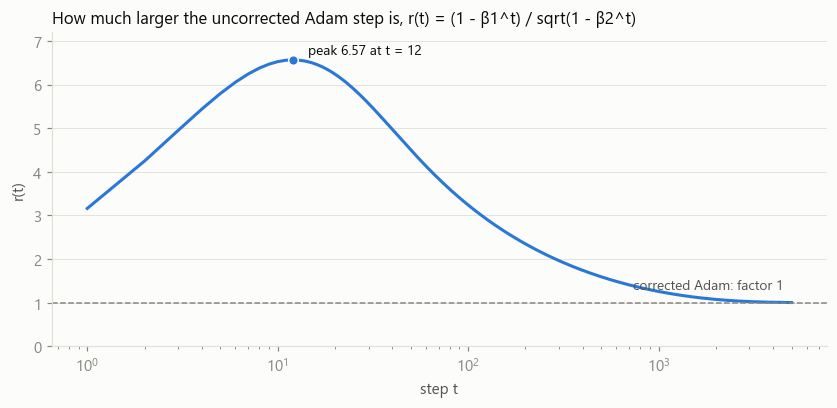

,t = 1,t = 10,t = 100,t = 1000,t = 5000
r(t),3.16,6.53,3.24,1.26,1.0


In [3]:
beta1, beta2 = 0.9, 0.999
t = np.arange(1, 5001)
r = (1 - beta1**t) / np.sqrt(1 - beta2**t)

fig, ax = plt.subplots(figsize=(7.5, 3.6), layout="constrained")
ax.plot(t, r, color=BLUE, linewidth=2)
ax.axhline(1, color=MUTED, linewidth=1, linestyle="--")
ax.text(4500, 1.3, "corrected Adam: factor 1", color=INK_2, ha="right", fontsize=9)
peak = r.argmax()
ax.scatter([t[peak]], [r[peak]], s=40, color=BLUE, edgecolors=SURFACE, zorder=3)
ax.annotate(f"peak {r[peak]:.2f} at t = {t[peak]}", (t[peak], r[peak]), xytext=(10, 4), textcoords="offset points", fontsize=9)
ax.set(xscale="log", xlabel="step t", ylabel="r(t)", ylim=(0, 7.2))
ax.grid(axis="y")
ax.set_title("How much larger the uncorrected Adam step is, r(t) = (1 - β1^t) / sqrt(1 - β2^t)", loc="left")
plt.show()

pd.Series(r[[0, 9, 99, 999, 4999]], index=[f"t = {k}" for k in (1, 10, 100, 1000, 5000)], name="r(t)").round(2).to_frame().T

## Problem 4 [Python]: The two-layer MLP in pure NumPy

The code below is a direct transcription of the mini-batch formulas of Problem 2. Parameters are stored in a dictionary, with the same shapes as in the theory ($W_1$ is $m\times d$, $W_2$ is $K\times m$). This is also the layout PyTorch uses, which makes Problem 5 straightforward. Labels are stored as integers; `np.eye(K)[y]` turns them into one-hot rows.

Two numerical details:
- **Stable softmax and cross-entropy.** The row maximum is subtracted from the logits before exponentiating (Problem 1, point 4). This changes nothing mathematically but prevents overflow.
- **Initialisation.** Weights are drawn from the Glorot (Xavier) uniform distribution $U\big(-\sqrt{6/(\text{fan-in}+\text{fan-out})},\,+\sqrt{6/(\text{fan-in}+\text{fan-out})}\big)$, which keeps the scale of the activations roughly constant from layer to layer for $\tanh$. Biases start at zero. The weights must not all start at the same value: then all hidden units would receive identical gradients and would stay identical forever.

In [4]:
def sigmoid(a):
    return 1.0 / (1.0 + np.exp(-a))


# Each activation is stored together with its derivative sigma'(a) (table in Problem 2).
ACTIVATIONS = {
    "tanh": (np.tanh, lambda a: 1.0 - np.tanh(a) ** 2),
    "sigmoid": (sigmoid, lambda a: sigmoid(a) * (1.0 - sigmoid(a))),
    "relu": (lambda a: np.maximum(a, 0.0), lambda a: (a > 0).astype(a.dtype)),
}


def init_params(d, m, K, rng):
    def glorot(fan_out, fan_in):
        limit = np.sqrt(6.0 / (fan_in + fan_out))
        return rng.uniform(-limit, limit, size=(fan_out, fan_in))
    return {"W1": glorot(m, d), "b1": np.zeros(m), "W2": glorot(K, m), "b2": np.zeros(K)}


def forward(params, X, activation="tanh"):
    sigma, _ = ACTIVATIONS[activation]
    A = X @ params["W1"].T + params["b1"]
    H = sigma(A)
    Z = H @ params["W2"].T + params["b2"]
    return {"A": A, "H": H, "Z": Z}


def log_softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)
    return Z - np.log(np.exp(Z).sum(axis=1, keepdims=True))


def loss_fn(params, X, y, activation="tanh", lam=0.0):
    log_P = log_softmax(forward(params, X, activation)["Z"])
    data_loss = -log_P[np.arange(len(y)), y].mean()
    return data_loss + 0.5 * lam * (np.sum(params["W1"] ** 2) + np.sum(params["W2"] ** 2))


def loss_and_grads(params, X, y, activation="tanh", lam=0.0):
    _, sigma_prime = ACTIVATIONS[activation]
    n, K = len(y), params["b2"].size
    cache = forward(params, X, activation)
    log_P = log_softmax(cache["Z"])
    loss = -log_P[np.arange(n), y].mean() + 0.5 * lam * (np.sum(params["W1"] ** 2) + np.sum(params["W2"] ** 2))

    D2 = (np.exp(log_P) - np.eye(K)[y]) / n                 # Delta_2 = (P - Y) / n
    D1 = (D2 @ params["W2"]) * sigma_prime(cache["A"])      # Delta_1 = (Delta_2 W_2) * sigma'(A)
    grads = {
        "W2": D2.T @ cache["H"] + lam * params["W2"],
        "b2": D2.sum(axis=0),
        "W1": D1.T @ X + lam * params["W1"],
        "b1": D1.sum(axis=0),
    }
    return loss, grads

### Gradient check by central finite differences

For one parameter entry $\theta_j$, Taylor's theorem gives

$$
\frac{L(\theta+he_j)-L(\theta-he_j)}{2h}=\frac{\partial L}{\partial\theta_j}+\frac{h^2}{6}\,\frac{\partial^3L}{\partial\theta_j^3}(\xi)
$$

for some $\xi$ between $\theta - he_j$ and $\theta + he_j$. The first-order and even terms cancel, so the error of the *central* difference is $O(h^2)$, compared with $O(h)$ for the one-sided difference $\big(L(\theta+he_j)-L(\theta)\big)/h$. Choosing $h$ is a trade-off: the truncation error $\sim h^2$ shrinks with $h$, but the rounding error, about $\epsilon_{\text{mach}}\lvert L\rvert/h\approx10^{-16}/h$, grows. With $h=10^{-5}$ in float64 both are around $10^{-10}$–$10^{-11}$.

The check below perturbs **every one** of the $64\cdot32+32+32\cdot10+10=2410$ parameters of a network with $m=32$ hidden units, on a batch of 32 training images, with an L2 penalty $\lambda=10^{-3}$ switched on so that the penalty gradient is tested too. For each parameter array it reports the relative error

$$
\text{rel.err}=\frac{\lVert g_{\text{analytic}}-g_{\text{numeric}}\rVert_2}{\lVert g_{\text{analytic}}\rVert_2+\lVert g_{\text{numeric}}\rVert_2}.
$$

A norm-based relative error is used rather than an entry-by-entry one, because some pixels are $0$ in every image of the batch. The corresponding columns of $\partial L/\partial W_1$ are then exactly $0$, and an entry-by-entry ratio would be $0/0$. ReLU is included as well, although it is not differentiable at $0$. The check is still valid as long as no pre-activation lies within $h$ of $0$, which has negligible probability for continuous random inputs.

In [5]:
def numerical_grads(params, X, y, activation, lam, h=1e-5):
    grads = {}
    for name, theta in params.items():
        g = np.zeros_like(theta)
        for idx in np.ndindex(theta.shape):
            original = theta[idx]
            theta[idx] = original + h
            loss_plus = loss_fn(params, X, y, activation, lam)
            theta[idx] = original - h
            loss_minus = loss_fn(params, X, y, activation, lam)
            theta[idx] = original
            g[idx] = (loss_plus - loss_minus) / (2 * h)
        grads[name] = g
    return grads


def relative_error(a, b):
    return np.linalg.norm(a - b) / max(np.linalg.norm(a) + np.linalg.norm(b), 1e-300)


rng = np.random.default_rng(SEED)
X_check, y_check = X_train[:32], y_train[:32]
rows = {}
for activation in ACTIVATIONS:
    params = init_params(D_IN, 32, N_CLASSES, rng)
    params = {k: v + 0.1 * rng.normal(size=v.shape) for k, v in params.items()}  # non-zero biases, so b1, b2 are tested too
    _, analytic = loss_and_grads(params, X_check, y_check, activation, lam=1e-3)
    numeric = numerical_grads(params, X_check, y_check, activation, lam=1e-3)
    rows[activation] = {name: relative_error(analytic[name], numeric[name]) for name in params}

grad_check = pd.DataFrame(rows).T[["W1", "b1", "W2", "b2"]]
assert (grad_check.values < 1e-5).all()
print(f"largest relative error over all activations and parameters: {grad_check.values.max():.1e} (required < 1e-05)")
grad_check.map(lambda v: f"{v:.1e}")

largest relative error over all activations and parameters: 9.6e-10 (required < 1e-05)


,W1,b1,W2,b2
tanh,3.4e-10,1.7e-10,2.4e-10,9.1e-11
sigmoid,9.6e-10,3.9e-10,1.8e-10,7.0e-11
relu,3.3e-10,1.6e-10,1.6e-10,6.6e-11


All relative errors are many orders of magnitude below the required $10^{-5}$, so the backward pass matches the derivatives of the forward pass.

### Training the NumPy network

The network is trained with plain mini-batch SGD (Problem 3) on the training split: $m=64$ hidden units, $\tanh$, learning rate $\eta=0.1$, batch size 32, 60 epochs. One **epoch** is one pass over the training set in a random order. All 60 random orders are drawn in advance and stored in `orders`, so that Problem 5 can feed the PyTorch network exactly the same batches. After every epoch the loss is evaluated on the whole training set and on the validation set.

In [6]:
HIDDEN, LR, BATCH, EPOCHS_NP = 64, 0.1, 32, 60
rng = np.random.default_rng(SEED)
params0 = init_params(D_IN, HIDDEN, N_CLASSES, rng)
orders = [rng.permutation(len(y_train)) for _ in range(EPOCHS_NP)]


def accuracy_np(params, X, y):
    return (forward(params, X)["Z"].argmax(axis=1) == y).mean()


def train_numpy(params, orders, lr, batch_size):
    params = {k: v.copy() for k, v in params.items()}
    history = {"train": [loss_fn(params, X_train, y_train)], "val": [loss_fn(params, X_val, y_val)]}
    for order in orders:
        for start in range(0, len(order), batch_size):
            idx = order[start:start + batch_size]
            _, grads = loss_and_grads(params, X_train[idx], y_train[idx])
            for name in params:
                params[name] -= lr * grads[name]
        history["train"].append(loss_fn(params, X_train, y_train))
        history["val"].append(loss_fn(params, X_val, y_val))
    return params, {k: np.array(v) for k, v in history.items()}


start = time.perf_counter()
params_np, hist_np = train_numpy(params0, orders, LR, BATCH)
print(f"NumPy training: {time.perf_counter() - start:.1f} s")
print(f"final loss: train {hist_np['train'][-1]:.4f}, validation {hist_np['val'][-1]:.4f}")
print(f"accuracy:   train {accuracy_np(params_np, X_train, y_train):.3f}, validation {accuracy_np(params_np, X_val, y_val):.3f}")

NumPy training: 0.4 s
final loss: train 0.0459, validation 0.1146
accuracy:   train 0.997, validation 0.964


## Problem 5 [Python]: The same network in PyTorch with autograd

In PyTorch only the **forward** pass is written by hand. During the forward pass, autograd records the operations that were applied to every tensor. `loss.backward()` then walks this record backwards and applies the chain rule, which is exactly the procedure carried out by hand in Problem 2.

`nn.Linear(d, m)` stores a weight of shape $m\times d$ and computes $xW^\top+b$, the same convention as our NumPy code. `F.cross_entropy` takes logits and averages $-\log p_c$ over the batch (Problem 1, point 4). Dropout is not used here (`p_drop=0`); it is needed in Problem 6.

For the two loss curves to be comparable, everything that is random must be the same in both implementations:
1. the initial weights are copied from the NumPy network,
2. the batches are taken from the same list `orders`,
3. both use the same optimiser (plain SGD, $\eta=0.1$) and float64 arithmetic.

Then the two implementations compute the same sequence of numbers, and they can differ only by floating-point rounding, because the operations are carried out in a different order.

In [7]:
class TwoLayerMLP(nn.Module):
    def __init__(self, d, m, K, p_drop=0.0):
        super().__init__()
        self.hidden = nn.Linear(d, m)
        self.dropout = nn.Dropout(p_drop)
        self.out = nn.Linear(m, K)

    def forward(self, x):
        return self.out(self.dropout(torch.tanh(self.hidden(x))))


def model_from_numpy(params):
    model = TwoLayerMLP(D_IN, params["W1"].shape[0], N_CLASSES)
    with torch.no_grad():
        model.hidden.weight.copy_(torch.from_numpy(params["W1"]))
        model.hidden.bias.copy_(torch.from_numpy(params["b1"]))
        model.out.weight.copy_(torch.from_numpy(params["W2"]))
        model.out.bias.copy_(torch.from_numpy(params["b2"]))
    return model


Xt_train, Xt_val, Xt_test = (torch.from_numpy(a) for a in (X_train, X_val, X_test))
yt_train, yt_val, yt_test = (torch.from_numpy(a) for a in (y_train, y_val, y_test))

# Gradients at initialisation on one batch: autograd versus the hand-derived formulas.
model = model_from_numpy(params0)
idx = orders[0][:BATCH]
F.cross_entropy(model(Xt_train[idx]), yt_train[idx]).backward()
_, grads_np = loss_and_grads(params0, X_train[idx], y_train[idx])
torch_grads = {"W1": model.hidden.weight.grad, "b1": model.hidden.bias.grad,
               "W2": model.out.weight.grad, "b2": model.out.bias.grad}
print("max |autograd - NumPy| on one batch:",
      {k: f"{np.abs(torch_grads[k].numpy() - grads_np[k]).max():.1e}" for k in grads_np})


def train_torch_sgd(model, orders, lr, batch_size):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    def evaluate():
        with torch.no_grad():
            return F.cross_entropy(model(Xt_train), yt_train).item(), F.cross_entropy(model(Xt_val), yt_val).item()

    history = {"train": [], "val": []}
    for epoch in range(len(orders) + 1):
        if epoch > 0:
            order = torch.from_numpy(orders[epoch - 1])
            for start in range(0, len(order), batch_size):
                idx = order[start:start + batch_size]
                loss = F.cross_entropy(model(Xt_train[idx]), yt_train[idx])
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        train_loss, val_loss = evaluate()
        history["train"].append(train_loss)
        history["val"].append(val_loss)
    return {k: np.array(v) for k, v in history.items()}


start = time.perf_counter()
hist_torch = train_torch_sgd(model_from_numpy(params0), orders, LR, BATCH)
print(f"PyTorch training: {time.perf_counter() - start:.1f} s")
max_diff = max(np.abs(hist_np[k] - hist_torch[k]).max() for k in ("train", "val"))
print(f"max |loss_NumPy - loss_PyTorch| over all {EPOCHS_NP + 1} evaluations: {max_diff:.1e}")

max |autograd - NumPy| on one batch: {'W2': '2.8e-17', 'b2': '1.4e-17', 'W1': '2.1e-17', 'b1': '2.1e-17'}


PyTorch training: 1.8 s
max |loss_NumPy - loss_PyTorch| over all 61 evaluations: 4.4e-16


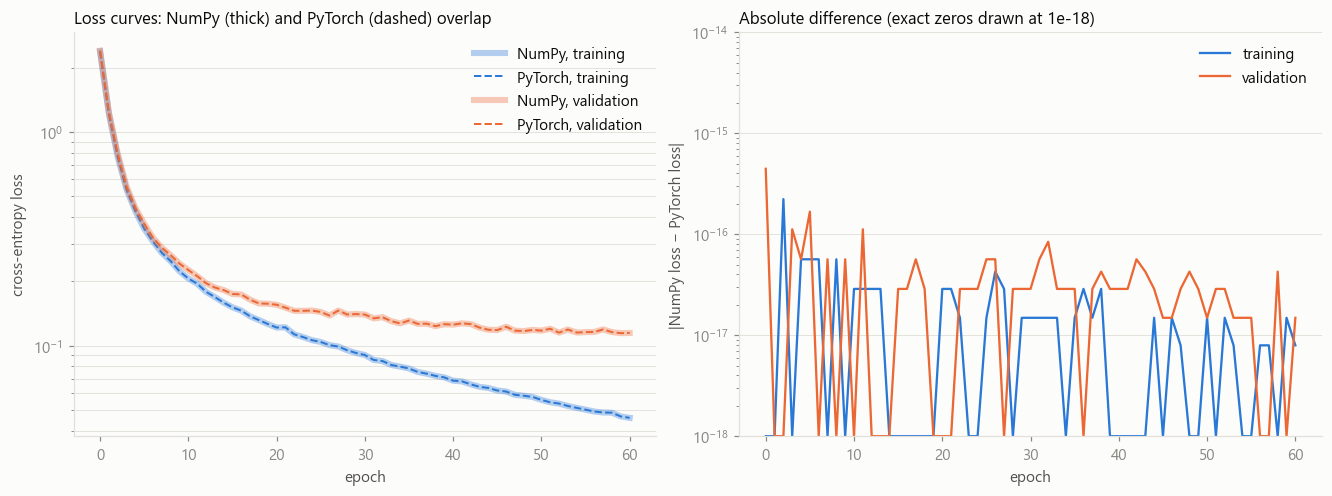

In [8]:
epochs = np.arange(EPOCHS_NP + 1)
fig, (ax_loss, ax_diff) = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")

for split, color in (("train", BLUE), ("val", ORANGE)):
    label = "training" if split == "train" else "validation"
    ax_loss.plot(epochs, hist_np[split], color=color, linewidth=4, alpha=0.35, label=f"NumPy, {label}")
    ax_loss.plot(epochs, hist_torch[split], color=color, linewidth=1.3, linestyle="--", label=f"PyTorch, {label}")
    ax_diff.plot(epochs, np.abs(hist_np[split] - hist_torch[split]) + 1e-18, color=color, linewidth=1.5, label=label)

ax_loss.set(xlabel="epoch", ylabel="cross-entropy loss", yscale="log")
ax_loss.grid(axis="y", which="both")
ax_loss.legend()
ax_loss.set_title("Loss curves: NumPy (thick) and PyTorch (dashed) overlap", loc="left")

ax_diff.set(xlabel="epoch", ylabel="|NumPy loss − PyTorch loss|", yscale="log", ylim=(1e-18, 1e-14))
ax_diff.grid(axis="y")
ax_diff.legend()
ax_diff.set_title("Absolute difference (exact zeros drawn at 1e-18)", loc="left")
plt.show()

The two loss curves coincide, and the difference stays at the level of float64 rounding ($\epsilon_{\text{mach}}\approx2.2\cdot10^{-16}$) for all 60 epochs. Small rounding differences do not grow over training here, because SGD with a small learning rate is a contracting process near a minimum. The hand-written backward pass and PyTorch's autograd therefore compute the same function and the same gradients.

In float32 the agreement would be only about $10^{-6}$–$10^{-7}$, because float32 has only about 7 significant digits.

## Problem 6 [Python]: Regularisation

### What is compared

A model **overfits** when it fits details of the training set that do not carry over to new data: the training loss keeps falling while the validation loss stops falling or rises. To make overfitting possible, this experiment uses a deliberately large network, $m=256$ hidden units (about $19\,000$ parameters for $1078$ training images), trained for 200 epochs with Adam ($\eta=10^{-3}$, batch size 32). Five configurations are compared:

| Configuration | What changes |
|---|---|
| **none** | plain training, no regularisation |
| **L2** | loss $+\;\frac\lambda2\left(\lVert W_1\rVert_F^2+\lVert W_2\rVert_F^2\right)$: large weights are penalised, so the learned function is smoother. Biases are not penalised, because they do not affect how sharply the output changes with the input. |
| **dropout** | during training, each hidden unit is set to $0$ with probability $p$, and the remaining ones are multiplied by $1/(1-p)$ so that the expected activation is unchanged. The network cannot rely on any single unit. At evaluation time dropout is switched off (`model.eval()`). |
| **early stopping** | training stops when the validation loss has not improved for 20 epochs (the *patience*), and the weights from the epoch with the lowest validation loss are restored. |
| **all three** | L2 + dropout + early stopping together |

**Three data splits.** The validation set is used for choosing $\lambda$ and $p$ and for early stopping. Because these decisions are made using the validation set, the validation score becomes optimistic. The final accuracies are therefore measured on the **test** set, which is used only once, at the end.

**Fair comparison.** For a given seed, every configuration starts from the same initial weights and sees the same batches in the same order. Training metrics are evaluated in eval mode (without dropout), so that they are comparable across configurations. Each configuration is run with 5 seeds, and the table reports the mean and standard deviation.

### Step 1: choosing $\lambda$ and $p$

A small grid is searched with 3 separate seeds. The selection criterion is the mean validation **cross-entropy** after 200 epochs, rather than validation accuracy. On 359 validation images, one image changes accuracy by $0.28$ percentage points, so accuracy is too coarse to separate the candidates, while the cross-entropy also measures how well calibrated the probabilities are.

In [9]:
HIDDEN_REG, EPOCHS_REG, LR_ADAM, BATCH_REG, PATIENCE = 256, 200, 1e-3, 32, 20


def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        Z = model(X)
        return F.cross_entropy(Z, y).item(), (Z.argmax(dim=1) == y).double().mean().item()


def train_regularised(seed, lam=0.0, p_drop=0.0, early_stopping=False, epochs=EPOCHS_REG):
    torch.manual_seed(seed)                                   # same initial weights for every configuration
    batch_gen = torch.Generator().manual_seed(seed)          # same batch order for every configuration
    model = TwoLayerMLP(D_IN, HIDDEN_REG, N_CLASSES, p_drop)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR_ADAM)
    history = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc")}
    best_val, best_epoch, best_state = np.inf, 0, None

    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(yt_train), generator=batch_gen)
        for start in range(0, len(order), BATCH_REG):
            idx = order[start:start + BATCH_REG]
            loss = F.cross_entropy(model(Xt_train[idx]), yt_train[idx])
            if lam > 0:
                loss = loss + 0.5 * lam * (model.hidden.weight.pow(2).sum() + model.out.weight.pow(2).sum())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        for split, (X, y) in (("train", (Xt_train, yt_train)), ("val", (Xt_val, yt_val))):
            loss_value, acc = evaluate(model, X, y)
            history[f"{split}_loss"].append(loss_value)
            history[f"{split}_acc"].append(acc)

        if history["val_loss"][-1] < best_val:
            best_val, best_epoch = history["val_loss"][-1], epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if early_stopping and epoch - best_epoch >= PATIENCE:
            break

    if early_stopping:
        model.load_state_dict(best_state)
    return model, {k: np.array(v) for k, v in history.items()}, (best_epoch if early_stopping else epoch)


start = time.perf_counter()
grid = [("L2", {"lam": lam}) for lam in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2)] + [("dropout", {"p_drop": p}) for p in (0.2, 0.5, 0.7, 0.8)]
search = []
for kind, kwargs in grid:
    val_losses, val_accs = [], []
    for seed in (100, 101, 102):
        model, _, _ = train_regularised(seed, **kwargs)
        val_loss, val_acc = evaluate(model, Xt_val, yt_val)
        val_losses.append(val_loss)
        val_accs.append(val_acc)
    search.append({"regulariser": kind, "value": next(iter(kwargs.values())),
                   "val loss": np.mean(val_losses), "val accuracy": np.mean(val_accs)})
search = pd.DataFrame(search)
print(f"grid search: {time.perf_counter() - start:.0f} s")

best = search.loc[search.groupby("regulariser")["val loss"].idxmin()].set_index("regulariser")["value"]
LAM, P_DROP = best["L2"], best["dropout"]
print(f"chosen: lambda = {LAM:g}, dropout p = {P_DROP:g}")
search.style.format({"value": "{:g}", "val loss": "{:.4f}", "val accuracy": "{:.3f}"}).hide(axis="index")

grid search: 149 s
chosen: lambda = 0.001, dropout p = 0.8


regulariser,value,val loss,val accuracy
L2,0.0001,0.1391,0.962
L2,0.0003,0.1281,0.959
L2,0.001,0.1240,0.958
L2,0.003,0.1443,0.962
L2,0.01,0.2321,0.956
dropout,0.2,0.1771,0.962
dropout,0.5,0.1577,0.963
dropout,0.7,0.1336,0.968
dropout,0.8,0.1199,0.968


**Reading the grid.** For L2 the validation loss has an interior minimum at $\lambda=10^{-3}$. Smaller values regularise too little, and $\lambda=10^{-2}$ regularises so strongly that the network can no longer fit the data well: the validation loss nearly doubles (0.232 against 0.124). That is under-fitting caused by the regulariser. For dropout the validation loss keeps decreasing up to the largest value tried, $p=0.8$, so the best dropout rate may lie even higher. The comparison below uses $p=0.8$, which may slightly understate how much dropout can help.

### Step 2: the five configurations, 5 seeds each

In [10]:
CONFIGS = {
    "none": {},
    "L2": {"lam": LAM},
    "dropout": {"p_drop": P_DROP},
    "early stopping": {"early_stopping": True},
    "all three": {"lam": LAM, "p_drop": P_DROP, "early_stopping": True},
}
SEEDS = range(5)

start = time.perf_counter()
results, histories = [], {}
for name, kwargs in CONFIGS.items():
    for seed in SEEDS:
        model, history, stop_epoch = train_regularised(seed, **kwargs)
        histories[name, seed] = history
        row = {"configuration": name, "seed": seed, "weights from epoch": stop_epoch}
        for split, (X, y) in {"train": (Xt_train, yt_train), "val": (Xt_val, yt_val), "test": (Xt_test, yt_test)}.items():
            row[f"{split} loss"], row[f"{split} accuracy"] = evaluate(model, X, y)
        results.append(row)
results = pd.DataFrame(results)
print(f"training 5 configurations x 5 seeds: {time.perf_counter() - start:.0f} s")

training 5 configurations x 5 seeds: 100 s


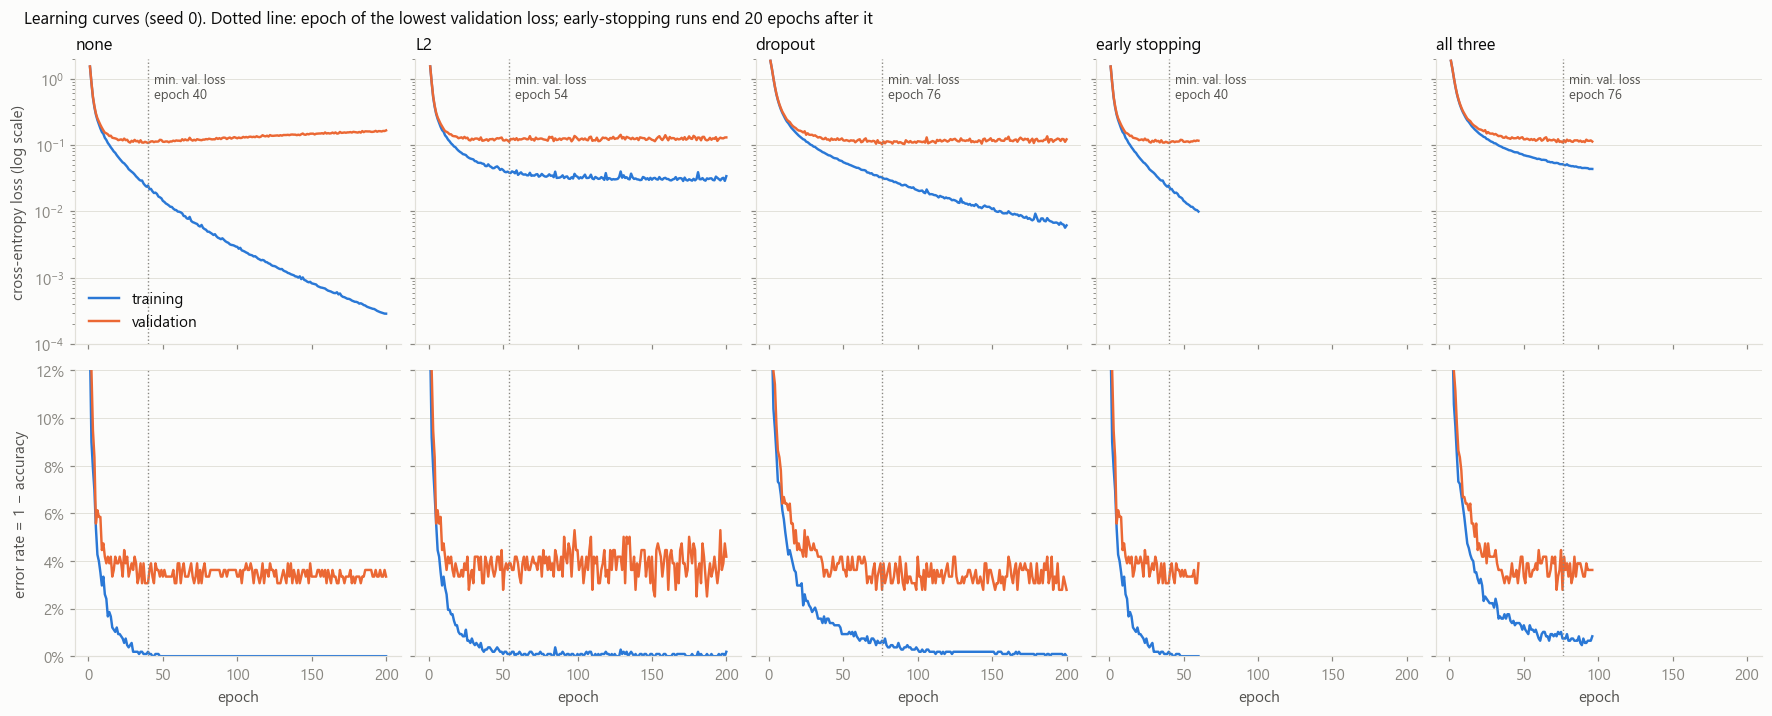

In [11]:
CONFIG_COLORS = {"none": INK_2, "L2": BLUE, "dropout": ORANGE, "early stopping": AQUA, "all three": VIOLET}

fig, axes = plt.subplots(2, 5, figsize=(16, 6.4), sharex=True, sharey="row", layout="constrained")
for col, name in enumerate(CONFIGS):
    h = histories[name, 0]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax_loss, ax_err = axes[0, col], axes[1, col]
    ax_loss.plot(ep, h["train_loss"], color=BLUE, linewidth=1.6, label="training")
    ax_loss.plot(ep, h["val_loss"], color=ORANGE, linewidth=1.6, label="validation")
    ax_err.plot(ep, 1 - h["train_acc"], color=BLUE, linewidth=1.6)
    ax_err.plot(ep, 1 - h["val_acc"], color=ORANGE, linewidth=1.6)
    best_epoch = int(np.argmin(h["val_loss"])) + 1
    for ax in (ax_loss, ax_err):
        ax.axvline(best_epoch, color=MUTED, linewidth=0.9, linestyle=":")
        ax.grid(axis="y", which="major")
    ax_loss.annotate(f"min. val. loss\nepoch {best_epoch}", (best_epoch, 1.2), xytext=(4, 0), textcoords="offset points",
                     fontsize=8.5, color=INK_2, va="top")
    ax_loss.set_title(name, loc="left")
    ax_err.set_xlabel("epoch")

axes[0, 0].set(yscale="log", ylim=(1e-4, 2), ylabel="cross-entropy loss (log scale)")
axes[1, 0].set(ylim=(0, 0.12), ylabel="error rate = 1 − accuracy")
axes[1, 0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
axes[0, 0].legend(loc="lower left")
fig.suptitle("Learning curves (seed 0). Dotted line: epoch of the lowest validation loss; early-stopping runs end 20 epochs after it",
             x=0.01, ha="left", fontsize=11)
plt.show()

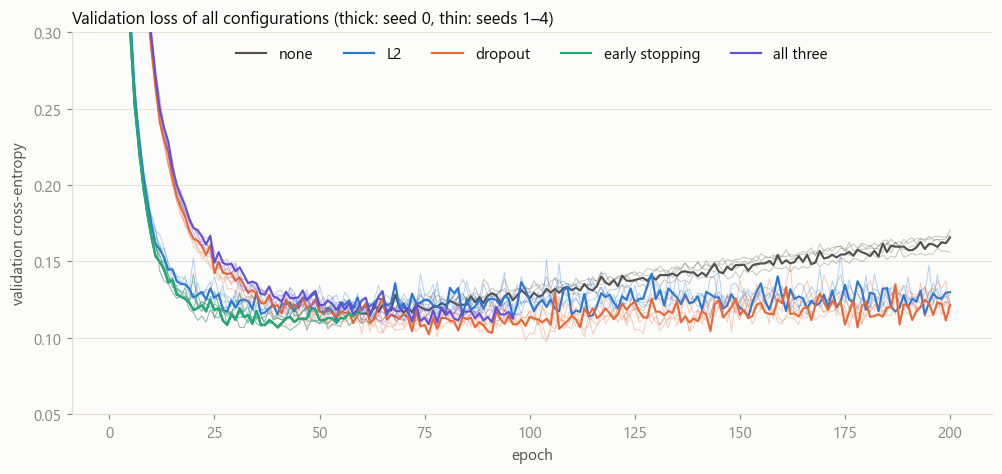

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
for name in CONFIGS:
    for seed in SEEDS:
        h = histories[name, seed]
        ax.plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], color=CONFIG_COLORS[name],
                linewidth=1.4 if seed == 0 else 0.6, alpha=1 if seed == 0 else 0.35, label=name if seed == 0 else None)
ax.set(xlabel="epoch", ylabel="validation cross-entropy", ylim=(0.05, 0.3))
ax.grid(axis="y")
ax.legend(ncol=5, loc="upper center")
ax.set_title("Validation loss of all configurations (thick: seed 0, thin: seeds 1–4)", loc="left")
plt.show()

In [13]:
summary = results.groupby("configuration", sort=False).agg(["mean", "std"])
table = pd.DataFrame({
    "weights from epoch": summary["weights from epoch"]["mean"].map("{:.0f}".format),
    **{f"{split} accuracy": [f"{100 * m:.2f} ± {100 * s:.2f}" for m, s in
                             zip(summary[f"{split} accuracy"]["mean"], summary[f"{split} accuracy"]["std"])]
       for split in ("train", "val", "test")},
    **{f"{split} loss": [f"{m:.3f} ± {s:.3f}" for m, s in
                         zip(summary[f"{split} loss"]["mean"], summary[f"{split} loss"]["std"])]
       for split in ("train", "test")},
}, index=summary.index)
print("mean ± standard deviation over 5 seeds; accuracies in %")
table

mean ± standard deviation over 5 seeds; accuracies in %


,weights from epoch,train accuracy,val accuracy,test accuracy,train loss,test loss
configuration,,,,,,
none,200,100.00 ± 0.00,96.60 ± 0.12,96.44 ± 0.50,0.000 ± 0.000,0.128 ± 0.002
L2,200,99.91 ± 0.07,95.71 ± 0.15,95.72 ± 0.15,0.030 ± 0.002,0.126 ± 0.004
dropout,200,99.94 ± 0.05,96.88 ± 0.31,96.44 ± 0.60,0.006 ± 0.000,0.098 ± 0.005
early stopping,37,99.89 ± 0.08,96.82 ± 0.32,97.56 ± 0.41,0.027 ± 0.005,0.112 ± 0.005
all three,75,99.11 ± 0.16,96.49 ± 0.54,97.00 ± 0.30,0.052 ± 0.004,0.117 ± 0.002


**How to read the table.** "Weights from epoch" is the epoch whose weights are evaluated. That is 200 without early stopping, and the epoch of the lowest validation loss with early stopping (training ran 20 epochs further). Two warnings about precision:
- The test set has 360 images, so one image is $0.28$ percentage points. A difference of 1 point corresponds to about 4 images.
- The standard deviation over seeds only measures the randomness of the initialisation, the batch order and the dropout masks. The data split is the same for all runs, so the true uncertainty about performance on new data is larger.

The test **loss** is a finer measurement than the test accuracy. It changes whenever a predicted probability changes, not only when an image moves from correct to wrong.

## Problem 7 [Analysis]: Over- and under-fitting, and which regulariser helped most

### Under-fitting

A model under-fits when it cannot yet fit even the training data. The training and validation losses are then both high and close to each other, and more capacity or more training would help. In the curves this happens in **the first 10–15 epochs of every run**: both losses are still falling steeply and both error rates are above 5%.

Too much regularisation causes under-fitting too, and the experiments show this in three places:
- In the grid search, $\lambda=10^{-2}$ gives a validation loss of $0.232$, almost twice the $0.124$ of $\lambda=10^{-3}$.
- With L2 the training loss stops at a plateau of about $0.03$ instead of going to zero. The penalty does not let the weights grow enough to fit the training set perfectly.
- "All three" has the highest training loss ($0.052$) and the lowest training accuracy ($99.1\%$) of all configurations. Three regularisers that each restrict the model add up to a model that fits the training data less well.

On this dataset, mild under-fitting of the training set is harmless, as the test results show.

### Over-fitting

The clearest example is the unregularised run ("none"). After about **epoch 40** the two loss curves separate:
- the training loss keeps falling by two more orders of magnitude, from about $2\cdot10^{-2}$ to $3\cdot10^{-4}$, and
- the validation loss rises from its minimum of about $0.11$ to about $0.165$, an increase of 50%.

The training error reached 0% by epoch 40. After that, the optimiser learns nothing that helps on new data.

**The validation error rate stays flat at about 3.5% while the validation loss rises.** The predicted class of a validation image almost never changes after epoch 40. What changes is the *confidence*. Problem 1 explains why. The gradient $p-y$ is zero only if $p=y$ exactly, and a softmax output satisfies $p_c=1$ only in the limit $z_c-z_k\to\infty$. On a perfectly classified training set, the optimiser therefore keeps pushing the logits apart, which means making the weights larger, and this never stops. On the handful of validation images that the network gets wrong, these ever more confident predictions put $p_c$ close to $0$, and $-\log p_c$ grows. So in this experiment over-fitting shows up as **over-confident probabilities**, not as more wrong decisions. Only a probability-based metric such as cross-entropy shows it.

### Which regulariser helped most?

The answer depends on what "helped" is measured by:

| Criterion | Best | Compared with no regularisation |
|---|---|---|
| test accuracy | early stopping, $97.56\pm0.41\%$ | $96.44\pm0.50\%$, i.e. about 4 more correct images out of 360 |
| test loss (quality of the probabilities) | dropout, $0.098$ | $0.128$, i.e. 23% lower |
| training cost | early stopping, about 57 epochs | 200 epochs |

**Overall, early stopping helped most on this dataset.** It is the only configuration whose accuracy gain (about 1.1 points) is clearly larger than the seed-to-seed standard deviation (0.4–0.5 points). It also reduces the test loss by 12%, cuts the training time by about 70%, and needs no hyperparameter search beyond the patience. The reason is the *kind* of over-fitting seen above. The decision boundaries are essentially final by about epoch 40, and everything after that only increases confidence. Early stopping removes exactly that phase and keeps the weights from the epoch where the validation loss is lowest. The validation-loss figure also shows that early stopping does not change training at all. Its curve is identical to the unregularised one until it stops, because both start from the same weights and see the same batches. Early stopping only decides *when to stop*. For gradient descent with small steps it can be shown to act approximately like an L2 penalty with $\lambda\propto1/(\eta t)$: stopping after fewer steps means the weights stay smaller.

**Dropout gave the best probabilities.** Its validation loss rises far more slowly after the minimum, and its test loss is the lowest. With $p=0.8$, only about 51 of the 256 hidden units are active in each training step, so the network is trained as a large family of random sub-networks that share their weights. At test time the full network, with the activations scaled appropriately, behaves approximately like an average over this family, and averaged predictions are less over-confident than those of any single network. However, dropout did not improve accuracy ($96.44\%$, the same as without regularisation).

**L2 helped least.** Its test loss is almost unchanged ($0.126$), and its accuracy is the lowest of all ($95.72\%$). Two reasons:
1. *L2 penalty is not the same as weight decay under Adam.* The penalty adds $\lambda W$ to the gradient, and Adam then divides the whole gradient by $\sqrt{\hat v_t}$ (Problem 3). Weights that receive large gradients are therefore shrunk much less than intended, and the strength of the penalty differs from weight to weight. Decoupled weight decay (AdamW), which shrinks the weights directly, is the usual remedy. The noisier validation error of the L2 run is consistent with this interaction.
2. *The penalty shrinks all weights equally.* Already at the $\lambda$ that is just strong enough to limit over-confidence ($10^{-3}$), it starts to cost accuracy (training loss plateau, slight under-fitting). A larger $\lambda$ makes this worse, as the grid shows.

**Combining all three did not beat early stopping alone** ($97.00\%$ against $97.56\%$). The three methods fight the same problem, growing weights and growing confidence, so their effects overlap. Stacked together, they push the model towards under-fitting. Moreover, $\lambda$ and $p$ were tuned separately, not jointly.

### Caveats

- The differences in accuracy are a few images out of 360, on a single data split. With another split, the ranking of configurations with similar accuracy could change. Only the larger effects should be trusted: the 23% lower loss with dropout, and the over-fitting of the unregularised loss.
- $\lambda$ and $p$ were chosen by validation loss, not accuracy, and the best dropout rate lay at the edge of the grid.
- Digits is a small, clean dataset that is almost perfectly separable, and every configuration reaches 96–98%. On the larger and noisier text, image and audio datasets later in the course, regularisation usually makes a bigger difference.